In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances

In [ ]:
### EV: *** THESE CONVENTIONS ARE NOT CONSISTENT YET ***
### EV: need to vectorize this for doing more points

def point_to_voxel(x, y, z, L):
    """
    Convert a point (x,y,z) in [-1,1]^3 to integer voxel indices in [0, L-1]^3.

    Inputs:
    x, y, z : float coordinates in [-1, 1]
    L : int grid size along each dimension

    Returns: (i, j, k) : tuple of ints, the voxel indices

    EV: TODO
    - need to fix conventions here to match typical RHG
    - make vectorized version
    """
    
    # Normalize from [-1,1] -> [0,1]
    xn = (x + 1) / 2
    yn = (y + 1) / 2
    zn = (z + 1) / 2

    # Scale to grid [0, L-1] and round/floor to integer index
    i = min(L-1, max(0, int(np.floor(xn * L))))
    j = min(L-1, max(0, int(np.floor(yn * L))))
    k = min(L-1, max(0, int(np.floor(zn * L))))

    return i, j, k

In [ ]:
### Generate rotated Gaussian blobs in 3D
### [x, y, z] grid on [-1, 1]^3
### theta = polar angle, phi = azimuthal angle

### initial point for Gaussian blob
p1 = np.array([0.0, 0.0, 0.7]).reshape(3, 1)

### angles to rotate Gaussian blob
theta = np.deg2rad(45)
phi = np.deg2rad(45)

Ry = transforms.rotate_y(theta)
Rz = transforms.rotate_z(phi)

R_theta_phi = Rz @ Ry

p2 = R_theta_phi @ p1

In [ ]:
### interpolate points to numpy grid

### size of numpy grid
L = 67

p1x, p1y, p1z = p1.flatten()  # EV: adding minus sign to flip axes for now
p2x, p2y, p2z = p2.flatten()

q1x, q1y, q1z = point_to_voxel(p1x, p1y, p1z, L)
q2x, q2y, q2z = point_to_voxel(p2x, p2y, p2z, L)

F = np.zeros((L,L,L))
G = np.zeros((L,L,L))

F[q1z, q1y, q1x] = 1
G[q2z, q2y, q2x] = 1

sigma = 2
z = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

F = utils.signal_convolution(F, z)
G = utils.signal_convolution(G, z)

In [ ]:
print("point coords: ", np.round((p1x,p1y,p1z), 3), np.round((p2x,p2y,p2z), 3))
print("voxel coords: ", (q1z,q1y,q1x), (q2z,q2y,q2x))

In [2]:
### alternative simple way of just picking voxel points manually

L = 67

F = np.zeros((L,L,L))
G = np.zeros((L,L,L))

# F[33, 16, 33] = 1
# G[33, 48, 33] = 1

# F[33, 33, 16] = 1
# G[33, 33, 50] = 1

# F[50, 33, 33] = 1
# G[33, 16, 33] = 1

F[48,16,33] = 1
G[14,40,10] = 1

sigma = 2
z = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

F = utils.signal_convolution(F, z)
G = utils.signal_convolution(G, z)

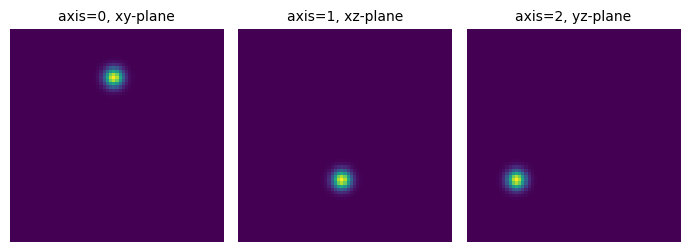

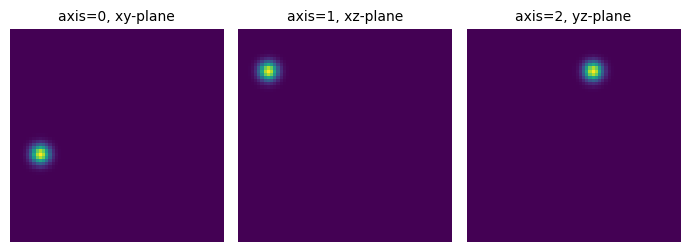

In [3]:
plots.orthogonal_2D_projection_plot(F)
plots.orthogonal_2D_projection_plot(G)

In [4]:
F_pdf = transforms.compute_projection_tensor_from_voxel_array(F)
F_cdf = transforms.pdf_tensor_to_cdf_tensor(F_pdf)
U = transforms.cdf_tensor_to_icdf_tensor(F_cdf)

G_pdf = transforms.compute_projection_tensor_from_voxel_array(G)
G_cdf = transforms.pdf_tensor_to_cdf_tensor(G_pdf)
V = transforms.cdf_tensor_to_icdf_tensor(G_cdf)

In [5]:
### Test rotations in either theta or phi individually by shifting tensor

n_phi, n_points, n_theta = U.shape

thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

dists_sw_theta = np.zeros(n_theta)
dists_sw_phi = np.zeros(n_phi)

for theta_idx in range(n_theta):
    V_theta = transforms.translate(V, 0, 0, theta_idx)
    dists_sw_theta[theta_idx] = np.mean((U - V_theta)**2)

for phi_idx in range(n_phi):
    V_phi = transforms.translate(V, phi_idx, 0, 0)
    dists_sw_phi[phi_idx] = np.mean((U - V_phi)**2)

In [6]:
dists_sw_theta = dists_sw_theta / np.amax(dists_sw_theta)
dists_sw_phi = dists_sw_phi / np.amax(dists_sw_phi)

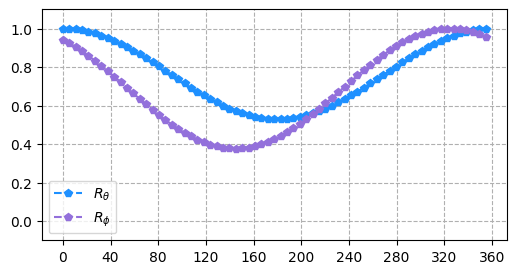

In [7]:
plt.figure(figsize=(6,3))
plt.plot(np.rad2deg(thetas), dists_sw_theta, 'p--', color='dodgerblue', label=r'$R_\theta$')
plt.plot(np.rad2deg(phis), dists_sw_phi, 'p--', color='mediumpurple', label=r'$R_\phi$')
plt.grid(which='major', linestyle='--')
plt.xticks(np.arange(0, 361, 40))
plt.ylim(-0.1, 1.1)
plt.legend()
plt.show()

In [8]:
print('  min_phi: ', np.rad2deg(phis[np.argmin(dists_sw_phi)]))
print('min_theta: ', np.rad2deg(phis[np.argmin(dists_sw_theta)]))

  min_phi:  145.07462686567166
min_theta:  182.6865671641791


In [9]:
### Loop through rotations of phi for each rotation of theta

n_phi, n_points, n_theta = U.shape

dists_sw_theta_phi = np.zeros((n_theta, n_phi))

t = time.time()

for theta_idx in range(n_theta):
    for phi_idx in range(n_phi):
        V_theta_phi = transforms.translate(V, phi_idx, 0, theta_idx)
        dists_sw_theta_phi[theta_idx, phi_idx] = np.mean((U - V_theta_phi)**2)

print('rotation distance time: ', time.time() - t)

rotation distance time:  3.507566213607788


In [10]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = np.round(np.rad2deg(distances.return_min_angles(dists_sw_theta_phi, thetas, phis)), 2)

min_theta =  0.0
  min_phi =  145.07




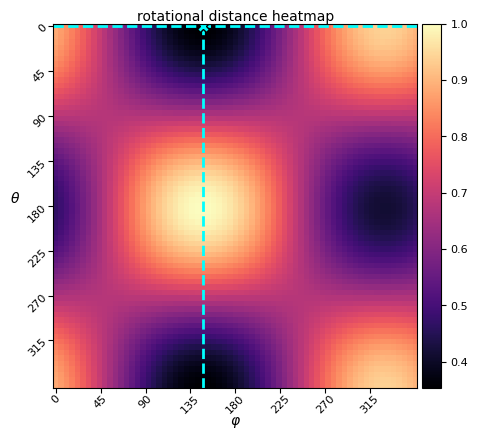

In [11]:
print('min_theta = ', min_theta)
print('  min_phi = ', min_phi)
print('\n')
plots.rotational_distance_heatmap(dists_sw_theta_phi)

In [15]:
### Next try fast rotations with 2D DFT
### axes are flipped compared to previous, is it the indexing of slice?
### should I add the conjugation

n_phi, n_points, n_theta = U.shape

C = np.zeros(U.shape)

t = time.time()

U_norm = np.linalg.norm(U)**2
V_norm = np.linalg.norm(V)**2

for s in range(n_points):
    
    U_slice = U[:, s, :]
    V_slice = V[:, s, :]
    
    C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.conj(np.fft.fft2(V_slice))).real
    # C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.fft.fft2(V_slice)).real

dists_sw_theta_phi = U_norm + V_norm - 2*np.sum(C, axis=1)

print('rotation distance time: ', time.time() - t)

rotation distance time:  0.07684087753295898


In [16]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = np.round(np.rad2deg(distances.return_min_angles(dists_sw_theta_phi, thetas, phis)), 2)

min_theta =  290.15
  min_phi =  0.0




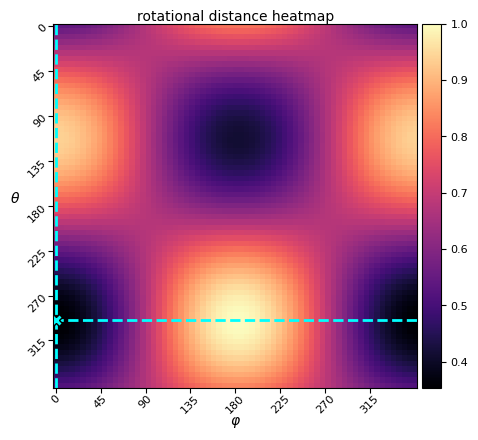

In [17]:
print('min_theta = ', min_theta)
print('  min_phi = ', min_phi)
print('\n')
plots.rotational_distance_heatmap(dists_sw_theta_phi)